# CSC 4110 Machine Learning: task notebook


| Field | Fill in |
|---|---|
| Task | 7 Unsupervised and Reinforcement Learning |
| Owner (name) | Festus Ligeyo |
| Registration number | COM/0018/23 |
| Group | G04 |
| Dataset | Credit Risk Dataset |
| Date started | 26 November 2026 |


**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [6]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G04"        # your group, two digits
UNIT = "7"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/MyDrive/CSC4110_G04


In [7]:
# Libraries used in most tasks, and a helper that saves every chart to outputs/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def save_fig(name):
    """Save the current chart as outputs/<name>.png, then show it."""
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [8]:

# Task 7: Load the prepared Credit Risk Dataset

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Use the dataset prepared in Task 2.2
DATA_FILE = "data/clean_credit.csv"

# Check the dataset exists before loading
if not os.path.isfile(DATA_FILE):
    raise FileNotFoundError(
        "Dataset not found. Check the shared Google Drive folder."
    )

# Load the dataset
df = pd.read_csv(DATA_FILE)

# Display dataset dimensions
print("Dataset shape:", df.shape)

# Show the first five loan records
display(df.head())

# Confirm the five clustering features exist
features = [
    "person_age",
    "log_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income"
]

print("\nClustering features available:",
      all(col in df.columns for col in features))

print("\nTask 7 dataset loaded successfully!")


Dataset shape: (32409, 25)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,...,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,age_band,log_income
0,21,9600,OWN,5.0,EDUCATION,1,1000,11.14,0,0.10,...,1,0,0,1,0,0,0,0,under 25,9.169518
1,25,9600,MORTGAGE,1.0,MEDICAL,2,5500,12.87,1,0.57,...,0,0,0,0,0,1,0,0,25-34,9.169518
2,23,65500,RENT,4.0,MEDICAL,2,35000,15.23,1,0.53,...,0,1,0,0,0,1,0,0,under 25,11.089805
3,24,54400,RENT,8.0,MEDICAL,2,35000,14.27,1,0.55,...,0,1,0,0,0,1,0,0,under 25,10.904119
4,21,9900,OWN,2.0,VENTURE,0,2500,7.14,1,0.25,...,1,0,0,0,0,0,0,1,under 25,9.200290



Clustering features available: True

Task 7 dataset loaded successfully!



## Task 7(a): K-Means Clustering

In this section, I select 5,000 loan records and standardise five numerical features before applying K-Means clustering.

The aim is to identify groups of borrowers with similar characteristics without using the interest-rate or loan-default targets.


In [9]:

# Task 7(a): Prepare 5,000 loan records for K-Means

from sklearn.preprocessing import StandardScaler

# Select exactly 5,000 records
sample_df = df.sample(
    n=5000,
    random_state=42
).copy()

# Select the five required features
features = [
    "person_age",
    "log_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income"
]

# Extract numerical data without prediction targets
X_cluster = sample_df[features].copy()

# Standardise the five features
cluster_scaler = StandardScaler()
X_scaled = cluster_scaler.fit_transform(X_cluster)

# Display results
print("Sample rows:", len(sample_df))
print("Number of features:", X_scaled.shape[1])
print("Scaled dataset shape:", X_scaled.shape)

print("\nFeatures used:")
print(features)

print("\nClustering data prepared successfully!")


Sample rows: 5000
Number of features: 5
Scaled dataset shape: (5000, 5)

Features used:
['person_age', 'log_income', 'person_emp_length', 'loan_amnt', 'loan_percent_income']

Clustering data prepared successfully!


k=2, Inertia=19666.73
k=3, Inertia=16209.07
k=4, Inertia=13985.35
k=5, Inertia=12189.56
k=6, Inertia=10841.33
k=7, Inertia=10139.77
k=8, Inertia=9511.92
k=9, Inertia=8994.52
k=10, Inertia=8547.15


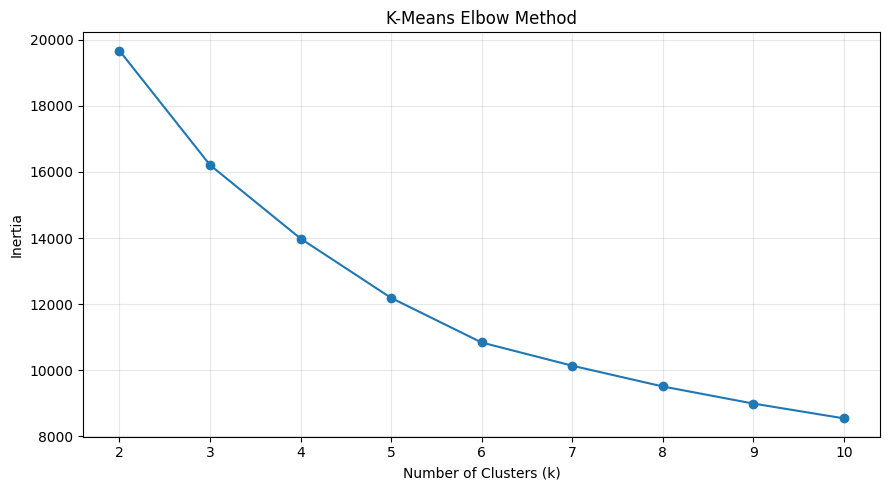


Saved: outputs/elbow.png


In [10]:

# Task 7(a): K-Means elbow method

from sklearn.cluster import KMeans

# Store the inertia for each cluster count
inertias = []

# Store trained K-Means models for later analysis
kmeans_models = {}

# Try cluster numbers from 2 to 10
k_values = range(2, 11)

for k in k_values:

    # Create and train the K-Means model
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    model.fit(X_scaled)

    # Store the model and its inertia
    kmeans_models[k] = model
    inertias.append(model.inertia_)

    print(f"k={k}, Inertia={model.inertia_:.2f}")

# Create the elbow graph
plt.figure(figsize=(9, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.title("K-Means Elbow Method")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/elbow.png", dpi=150)

# Display the graph
plt.show()

print("\nSaved: outputs/elbow.png")



## Task 7(a): Silhouette Scores and Best Number of Clusters

In this section, I calculate silhouette scores for K-Means models with 2 to 10 clusters.

I select the number of clusters with the highest silhouette score and examine the average borrower characteristics in each cluster.


In [11]:

# Task 7(a): Calculate silhouette scores

from sklearn.metrics import silhouette_score

# Store silhouette scores for each cluster count
sil_scores = {}

# Evaluate the K-Means models trained earlier
for k in range(2, 11):

    # Retrieve the fitted K-Means model
    model = kmeans_models[k]

    # Calculate silhouette score using a reproducible
    # sample of 1,500 records to save computation
    score = silhouette_score(
        X_scaled,
        model.labels_,
        sample_size=1500,
        random_state=42
    )

    # Store the score
    sil_scores[k] = score

    print(f"k={k}: Silhouette Score={score:.4f}")

# Find the number of clusters with highest score
best_k = max(sil_scores, key=sil_scores.get)

print("\nBEST NUMBER OF CLUSTERS")
print("Best k:", best_k)
print("Best silhouette score:", round(sil_scores[best_k], 4))

# Retrieve the best trained model
best_kmeans = kmeans_models[best_k]

# Assign cluster labels to the sampled data
sample_df["cluster"] = best_kmeans.labels_

print("\nBORROWERS IN EACH CLUSTER")
print(sample_df["cluster"].value_counts().sort_index())

print("\nSilhouette analysis completed successfully!")


k=2: Silhouette Score=0.2416
k=3: Silhouette Score=0.2146
k=4: Silhouette Score=0.2095
k=5: Silhouette Score=0.2263
k=6: Silhouette Score=0.2135
k=7: Silhouette Score=0.1954
k=8: Silhouette Score=0.1947
k=9: Silhouette Score=0.1949
k=10: Silhouette Score=0.1967

BEST NUMBER OF CLUSTERS
Best k: 2
Best silhouette score: 0.2416

BORROWERS IN EACH CLUSTER
cluster
0    3269
1    1731
Name: count, dtype: int64

Silhouette analysis completed successfully!


In [12]:

# Task 7(a): Analyse the selected clusters

# Calculate the mean of each required feature
cluster_means = sample_df.groupby("cluster")[features].mean()

print("AVERAGE BORROWER CHARACTERISTICS BY CLUSTER")
display(cluster_means.round(2))

# Calculate the number of borrowers in each cluster
cluster_sizes = sample_df.groupby("cluster").size()

# Calculate historical default rates for interpretation
# Loan status was NOT used to train the clusters
default_rates = (
    sample_df.groupby("cluster")["loan_status"].mean() * 100
)

# Combine cluster sizes and default rates
cluster_summary = pd.DataFrame({
    "Number of Borrowers": cluster_sizes,
    "Default Rate (%)": default_rates
})

print("\nCLUSTER SIZES AND DEFAULT RATES")
display(cluster_summary.round(2))

print("\nCluster analysis completed successfully!")


AVERAGE BORROWER CHARACTERISTICS BY CLUSTER


,person_age,log_income,person_emp_length,loan_amnt,loan_percent_income
cluster,,,,,
0,27.68,10.89,4.62,6199.24,0.11
1,27.92,10.98,5.12,16057.24,0.27



CLUSTER SIZES AND DEFAULT RATES


,Number of Borrowers,Default Rate (%)
cluster,,
0,3269,15.30
1,1731,33.62



Cluster analysis completed successfully!



### Task 7(a): Interpretation of K-Means Clusters

The silhouette analysis selected k = 2 with a score of 0.2416.

**Cluster 0: Smaller Loans and Lower Loan-to-Income Ratios**

This cluster contains 3,269 borrowers with an average loan amount of 6,199.24 and an average loan-to-income ratio of 0.11. Its historical default rate is 15.30%.

**Cluster 1: Larger Loans and Higher Loan-to-Income Ratios**

This cluster contains 1,731 borrowers with an average loan amount of 16,057.24 and an average loan-to-income ratio of 0.27. Its historical default rate is 33.62%.

Cluster 1 has a higher historical default rate, but these are exploratory associations rather than proof that belonging to the cluster causes default.

The silhouette score indicates that the groups have some overlap.



## Task 7(b): Principal Component Analysis (PCA)

In this section, I reduce the five standardised borrower features into two principal components.

I use PCA to visualise the K-Means clusters in two dimensions and report how much variation is explained by the two components.


In [13]:

# Task 7(b): PCA dimensionality reduction

from sklearn.decomposition import PCA

# Create PCA with two principal components
pca = PCA(
    n_components=2,
    random_state=42
)

# Fit PCA and transform the scaled dataset
X_pca = pca.fit_transform(X_scaled)

# Display the resulting dimensions
print("PCA transformed shape:", X_pca.shape)

# Display explained variance ratios
print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

# Calculate total variance explained
total_variance = pca.explained_variance_ratio_.sum()

print("\nTotal variance explained:",
      round(total_variance * 100, 2), "%")

# Store principal components in the sampled dataset
sample_df["PC1"] = X_pca[:, 0]
sample_df["PC2"] = X_pca[:, 1]

print("\nPCA completed successfully!")


PCA transformed shape: (5000, 2)

Explained variance ratio:
[0.32011171 0.30149054]

Total variance explained: 62.16 %

PCA completed successfully!


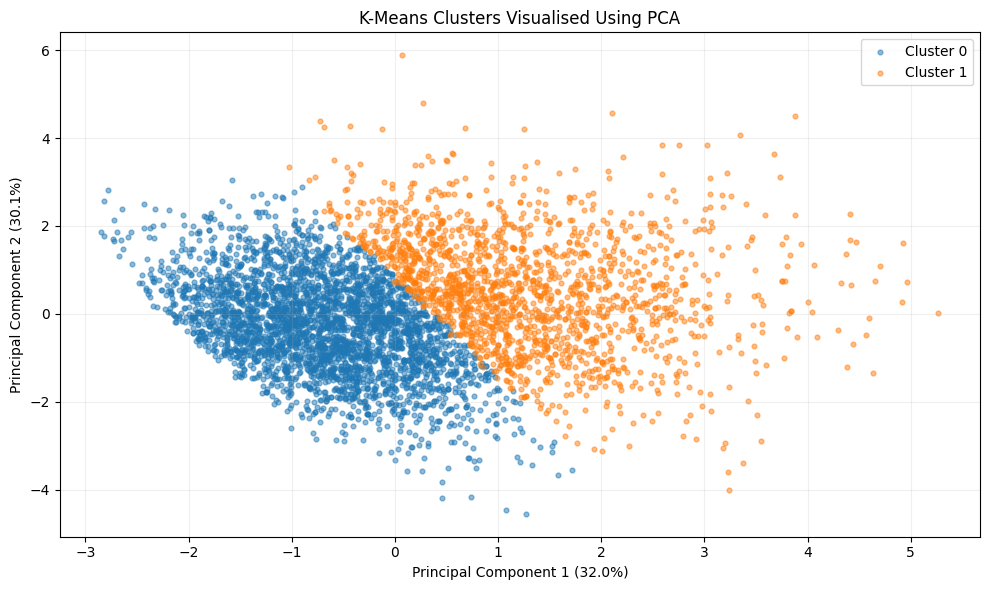

Saved: outputs/pca_clusters.png


In [14]:

# Task 7(b): Plot the K-Means clusters using PCA

# Create the graph
plt.figure(figsize=(10, 6))

# Plot each cluster separately
for cluster_id in sorted(sample_df["cluster"].unique()):

    # Select borrowers in this cluster
    subset = sample_df[
        sample_df["cluster"] == cluster_id
    ]

    # Plot both principal components
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        s=12,
        alpha=0.5,
        label=f"Cluster {cluster_id}"
    )

# Add the chart title and labels
plt.title("K-Means Clusters Visualised Using PCA")

plt.xlabel(
    f"Principal Component 1 "
    f"({pca.explained_variance_ratio_[0] * 100:.1f}%)"
)

plt.ylabel(
    f"Principal Component 2 "
    f"({pca.explained_variance_ratio_[1] * 100:.1f}%)"
)

# Add the legend and grid
plt.legend()
plt.grid(alpha=0.2)

# Save the required chart
plt.tight_layout()
plt.savefig(
    "outputs/pca_clusters.png",
    dpi=150
)

# Show the graph
plt.show()

print("Saved: outputs/pca_clusters.png")



## Task 7(c): DBSCAN Clustering

In this section, I use DBSCAN to identify groups of similar borrowers and unusual records.

I first create a 5-nearest-neighbour distance plot to help select the eps parameter, then compare DBSCAN with K-Means clustering.


5-NEAREST-NEIGHBOUR DISTANCE SUMMARY
75th percentile: 0.5100
80th percentile: 0.5520
85th percentile: 0.6205
90th percentile: 0.7170
95th percentile: 0.9186
97th percentile: 1.0721
99th percentile: 1.4468


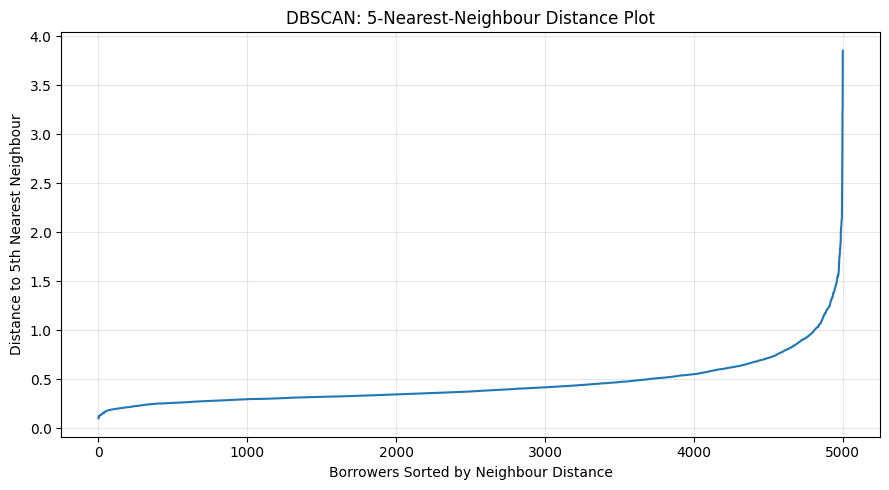

Saved: outputs/dbscan_k_distance.png


In [15]:

# Task 7(c): Find a suitable eps using a k-distance plot

from sklearn.neighbors import NearestNeighbors

# Use 5 neighbours because DBSCAN requires min_samples=5
neighbors = NearestNeighbors(n_neighbors=5)

# Fit on the same 5,000 scaled loan records
neighbors.fit(X_scaled)

# Calculate distances to the five nearest neighbours
distances, indices = neighbors.kneighbors(X_scaled)

# Extract and sort the fifth-neighbour distances
k_distances = np.sort(distances[:, 4])

# Display useful distance percentiles
print("5-NEAREST-NEIGHBOUR DISTANCE SUMMARY")

for percentile in [75, 80, 85, 90, 95, 97, 99]:
    value = np.percentile(k_distances, percentile)
    print(f"{percentile}th percentile: {value:.4f}")

# Plot sorted fifth-neighbour distances
plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(k_distances) + 1),
    k_distances
)

plt.title("DBSCAN: 5-Nearest-Neighbour Distance Plot")
plt.xlabel("Borrowers Sorted by Neighbour Distance")
plt.ylabel("Distance to 5th Nearest Neighbour")

plt.grid(alpha=0.3)

# Save the supporting graph
plt.tight_layout()
plt.savefig("outputs/dbscan_k_distance.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/dbscan_k_distance.png")


In [16]:

# Task 7(c): Perform DBSCAN clustering

from sklearn.cluster import DBSCAN
import numpy as np
import pandas as pd

# Choose eps using the k-distance graph
eps_value = 1.0

# Create the DBSCAN model
dbscan = DBSCAN(
    eps=eps_value,
    min_samples=5
)

# Train DBSCAN on the same scaled features
dbscan_labels = dbscan.fit_predict(X_scaled)

# Store DBSCAN labels in our sampled dataset
sample_df["dbscan_cluster"] = dbscan_labels

# Count clusters, excluding noise (-1)
unique_labels = set(dbscan_labels)

dbscan_clusters = len(
    unique_labels - {-1}
)

# Count noise points
noise_points = int(np.sum(dbscan_labels == -1))

# Calculate percentage of noise points
noise_percentage = (
    noise_points / len(dbscan_labels)
) * 100

# Display results
print("DBSCAN CLUSTERING RESULTS")
print("Eps value:", eps_value)
print("Minimum samples:", 5)

print("\nNumber of DBSCAN clusters:", dbscan_clusters)
print("Number of noise points:", noise_points)
print("Noise percentage:", round(noise_percentage, 2), "%")

# Display number of borrowers in each cluster
print("\nDBSCAN CLUSTER SIZES")
print(
    sample_df["dbscan_cluster"]
    .value_counts()
    .sort_index()
)

# Compare DBSCAN with K-Means
print("\nK-MEANS VS DBSCAN")
print("K-Means clusters:", best_k)
print("DBSCAN clusters:", dbscan_clusters)
print("DBSCAN noise points:", noise_points)

print("\nDBSCAN completed successfully!")


DBSCAN CLUSTERING RESULTS
Eps value: 1.0
Minimum samples: 5

Number of DBSCAN clusters: 1
Number of noise points: 112
Noise percentage: 2.24 %

DBSCAN CLUSTER SIZES
dbscan_cluster
-1     112
 0    4888
Name: count, dtype: int64

K-MEANS VS DBSCAN
K-Means clusters: 2
DBSCAN clusters: 1
DBSCAN noise points: 112

DBSCAN completed successfully!


In [17]:

# Task 7(c): Analyse DBSCAN cluster characteristics

# Calculate the mean values of each feature by DBSCAN group
dbscan_means = sample_df.groupby(
    "dbscan_cluster"
)[features].mean()

print("DBSCAN AVERAGE BORROWER CHARACTERISTICS")
display(dbscan_means.round(2))

# Calculate historical default rates by DBSCAN group
dbscan_summary = sample_df.groupby(
    "dbscan_cluster"
).agg(
    borrowers=("loan_status", "size"),
    default_rate=("loan_status", "mean")
)

# Convert default rate to a percentage
dbscan_summary["default_rate"] *= 100

print("\nDBSCAN GROUP SIZES AND DEFAULT RATES")
display(dbscan_summary.round(2))

# Examine unusual borrowers identified as noise
noise_df = sample_df[
    sample_df["dbscan_cluster"] == -1
]

print("\nNOISE POINT ANALYSIS")
print("Unusual records identified:", len(noise_df))

if len(noise_df) > 0:
    print("\nAverage characteristics of noise points:")
    display(noise_df[features].mean().round(2))

print("\nDBSCAN analysis completed successfully!")


DBSCAN AVERAGE BORROWER CHARACTERISTICS


,person_age,log_income,person_emp_length,loan_amnt,loan_percent_income
dbscan_cluster,,,,,
-1,44.32,10.85,10.30,15233.26,0.26
0,27.38,10.92,4.67,9483.28,0.17



DBSCAN GROUP SIZES AND DEFAULT RATES


,borrowers,default_rate
dbscan_cluster,,
-1,112,42.86
0,4888,21.15



NOISE POINT ANALYSIS
Unusual records identified: 112

Average characteristics of noise points:


,0
person_age,44.32
log_income,10.85
person_emp_length,10.30
loan_amnt,15233.26
loan_percent_income,0.26



DBSCAN analysis completed successfully!



### Task 7(c): DBSCAN Interpretation

I selected eps = 1.0 based on the bend in the 5-nearest-neighbour distance graph and used min_samples = 5.

DBSCAN groups borrowers according to how densely their records occur in the standardised feature space.

Unlike K-Means, DBSCAN does not require the number of clusters to be specified in advance.

K-Means divided my sample into two clusters, while DBSCAN identified groups based on density and labelled unusual records as noise (-1).

DBSCAN may be more useful for identifying applicants with unusual combinations of characteristics because it can separate isolated records from dense groups.

A noise label does not necessarily mean that a borrower will default.



### Task 7(c): DBSCAN Interpretation

I selected eps = 1.0 from the 5-nearest-neighbour distance plot and used min_samples = 5.

K-Means divided the sample into two clusters, while DBSCAN identified one main cluster containing 4,888 borrowers and 112 noise points.

The noise points represented 2.24% of the 5,000 borrowers.

The main cluster had an average age of 27.38 years, an average loan amount of 9,483.28 and a historical default rate of 21.15%.

The noise group had an average age of 44.32 years, an average loan amount of 15,233.26 and a historical default rate of 42.86%.

DBSCAN is useful for identifying unusual applicants because it can distinguish isolated records from densely grouped records.

However, unusual applicants should receive further review rather than being automatically classified as likely defaulters.



## Task 7(d): Q-Learning on FrozenLake

This section implements Q-learning using the FrozenLake-v1 environment.

I train an agent for 2,000 episodes with learning rate alpha = 0.1, discount factor gamma = 0.99 and a decaying epsilon-greedy exploration policy.

The first experiment uses is_slippery=False.


In [18]:

# Task 7(d): Q-learning on non-slippery FrozenLake

import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym

# Use the last three digits of COM/0018/23
SEED = 823

# Create the non-slippery FrozenLake environment
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=False
)

# Get the number of states and actions
n_states = env.observation_space.n
n_actions = env.action_space.n

# Initialise the required Q-table
Q = np.zeros((n_states, n_actions))

# Set the learning parameters
alpha = 0.1
gamma = 0.99
episodes = 2000

# Create a reproducible random generator
rng = np.random.default_rng(SEED)

# Store success results
successes = []
success_rates = []

# Save one real, non-zero Q-learning update
q_update_example = None

# Train the agent for 2,000 episodes
for episode in range(episodes):

    # Reset the environment for this episode
    state, info = env.reset(seed=SEED + episode)

    # Gradually reduce exploration
    epsilon = max(
        0.05,
        1.0 - 0.95 * episode / (episodes - 1)
    )

    # Try up to 100 actions per episode
    reward = 0

    for step in range(100):

        # Explore or choose the best known action
        if rng.random() < epsilon:
            action = int(rng.integers(n_actions))
        else:
            choices = np.flatnonzero(
                np.isclose(Q[state], Q[state].max())
            )
            action = int(rng.choice(choices))

        # Take the action
        next_state, reward, terminated, truncated, info = (
            env.step(action)
        )

        # Record the value before the update
        q_before = float(Q[state, action])

        # Find the best next Q value
        best_next_q = (
            0.0 if terminated
            else float(np.max(Q[next_state]))
        )

        # Apply the Q-learning update
        q_after = q_before + alpha * (
            reward + gamma * best_next_q - q_before
        )

        # Update the Q-table
        Q[state, action] = q_after

        # Save an informative update for manual checking
        if (q_update_example is None and
                abs(q_after - q_before) > 1e-12):
            q_update_example = {
                "state": int(state),
                "action": int(action),
                "before": q_before,
                "reward": float(reward),
                "best_next": best_next_q,
                "after": float(q_after)
            }

        # Move to the next state
        state = next_state

        # Stop if the episode finishes
        if terminated or truncated:
            break

    # Record whether the agent reached the goal
    successes.append(int(reward == 1))

    # Calculate success rate after each 100 episodes
    if (episode + 1) % 100 == 0:
        rate = np.mean(successes[-100:])
        success_rates.append(rate)

# Close the training environment
env.close()

# Display training results
print("Q-LEARNING TRAINING RESULTS")

print("Q-table shape:", Q.shape)
print("Episodes trained:", episodes)
print("Learning rate:", alpha)
print("Discount factor:", gamma)

print("\nSuccess rates per 100 episodes:")
for i, rate in enumerate(success_rates, start=1):
    print(f"Episodes {(i-1)*100+1}-{i*100}: {rate:.2%}")

print("\nFinal 100-episode success rate:",
      f"{success_rates[-1]:.2%}")

print("\nTraining completed successfully!")


Q-LEARNING TRAINING RESULTS
Q-table shape: (16, 4)
Episodes trained: 2000
Learning rate: 0.1
Discount factor: 0.99

Success rates per 100 episodes:
Episodes 1-100: 0.00%
Episodes 101-200: 1.00%
Episodes 201-300: 3.00%
Episodes 301-400: 4.00%
Episodes 401-500: 6.00%
Episodes 501-600: 13.00%
Episodes 601-700: 23.00%
Episodes 701-800: 24.00%
Episodes 801-900: 24.00%
Episodes 901-1000: 35.00%
Episodes 1001-1100: 32.00%
Episodes 1101-1200: 55.00%
Episodes 1201-1300: 51.00%
Episodes 1301-1400: 55.00%
Episodes 1401-1500: 64.00%
Episodes 1501-1600: 83.00%
Episodes 1601-1700: 72.00%
Episodes 1701-1800: 83.00%
Episodes 1801-1900: 92.00%
Episodes 1901-2000: 94.00%

Final 100-episode success rate: 94.00%

Training completed successfully!


In [19]:

# Task 7(d): Display the learned FrozenLake policy

# FrozenLake action numbers:
# 0 = Left, 1 = Down, 2 = Right, 3 = Up
arrows = ["←", "↓", "→", "↑"]

# Create the environment to inspect its grid
policy_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=False
)

# Read the lake layout
lake = policy_env.unwrapped.desc

print("LEARNED Q-LEARNING POLICY")
print("S = Start, H = Hole, G = Goal")

for row in range(4):

    policy_row = []

    for col in range(4):

        # Convert row and column to the state number
        state = row * 4 + col

        # Get the map symbol
        symbol = lake[row, col].decode("utf-8")

        # Keep holes and goal labelled
        if symbol in ["H", "G"]:
            policy_row.append(symbol)
        else:
            best_action = int(np.argmax(Q[state]))
            policy_row.append(arrows[best_action])

    print("  ".join(policy_row))

policy_env.close()

# Display the saved training update
print("\nQ-LEARNING UPDATE EXAMPLE")
print(q_update_example)


LEARNED Q-LEARNING POLICY
S = Start, H = Hole, G = Goal
→  →  ↓  ←
↑  H  ↓  H
→  →  ↓  H
H  →  →  G

Q-LEARNING UPDATE EXAMPLE
{'state': 14, 'action': 2, 'before': 0.0, 'reward': 1.0, 'best_next': 0.0, 'after': 0.1}



## Task 7(d): Slippery FrozenLake Experiment

This section repeats Q-learning with is_slippery=True.

I compare learning success rates with the non-slippery environment to investigate how uncertain movements affect an agent's ability to reach the goal.


In [20]:

# Task 7(d): Q-learning on slippery FrozenLake

# Create the slippery environment
slippery_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

# Initialise a separate Q-table
Q_slippery = np.zeros((16, 4))

# Store success results
slippery_successes = []
slippery_success_rates = []

# Use a reproducible random generator
rng_slippery = np.random.default_rng(SEED)

# Train for 2,000 episodes
for episode in range(episodes):

    state, info = slippery_env.reset(
        seed=SEED + episode
    )

    # Gradually reduce exploration
    epsilon = max(
        0.05,
        1.0 - 0.95 * episode / (episodes - 1)
    )

    reward = 0

    # Limit each episode to 100 steps
    for step in range(100):

        # Choose an exploratory or greedy action
        if rng_slippery.random() < epsilon:
            action = int(rng_slippery.integers(4))
        else:
            choices = np.flatnonzero(
                np.isclose(
                    Q_slippery[state],
                    Q_slippery[state].max()
                )
            )
            action = int(rng_slippery.choice(choices))

        # Take the action on slippery ice
        next_state, reward, terminated, truncated, info = (
            slippery_env.step(action)
        )

        # Find the best future Q-value
        best_next_q = (
            0.0 if terminated or truncated
            else np.max(Q_slippery[next_state])
        )

        # Update the Q-value
        Q_slippery[state, action] += alpha * (
            reward
            + gamma * best_next_q
            - Q_slippery[state, action]
        )

        # Move to the next state
        state = next_state

        if terminated or truncated:
            break

    # Record whether the goal was reached
    slippery_successes.append(int(reward == 1))

    # Calculate success after every 100 episodes
    if (episode + 1) % 100 == 0:
        rate = np.mean(slippery_successes[-100:])
        slippery_success_rates.append(rate)

slippery_env.close()

# Display results
print("SLIPPERY FROZENLAKE RESULTS")
print("Episodes:", episodes)
print("Q-table shape:", Q_slippery.shape)

print("\nSuccess rates per 100 episodes:")

for i, rate in enumerate(slippery_success_rates, 1):
    print(f"Episodes {i*100-99}-{i*100}: {rate:.2%}")

print("\nFINAL COMPARISON")
print("Non-slippery:", f"{success_rates[-1]:.2%}")
print("Slippery:", f"{slippery_success_rates[-1]:.2%}")

print("\nSlippery training completed!")


SLIPPERY FROZENLAKE RESULTS
Episodes: 2000
Q-table shape: (16, 4)

Success rates per 100 episodes:
Episodes 1-100: 3.00%
Episodes 101-200: 1.00%
Episodes 201-300: 3.00%
Episodes 301-400: 2.00%
Episodes 401-500: 1.00%
Episodes 501-600: 2.00%
Episodes 601-700: 2.00%
Episodes 701-800: 3.00%
Episodes 801-900: 6.00%
Episodes 901-1000: 4.00%
Episodes 1001-1100: 6.00%
Episodes 1101-1200: 10.00%
Episodes 1201-1300: 10.00%
Episodes 1301-1400: 9.00%
Episodes 1401-1500: 11.00%
Episodes 1501-1600: 15.00%
Episodes 1601-1700: 22.00%
Episodes 1701-1800: 27.00%
Episodes 1801-1900: 28.00%
Episodes 1901-2000: 48.00%

FINAL COMPARISON
Non-slippery: 94.00%
Slippery: 48.00%

Slippery training completed!


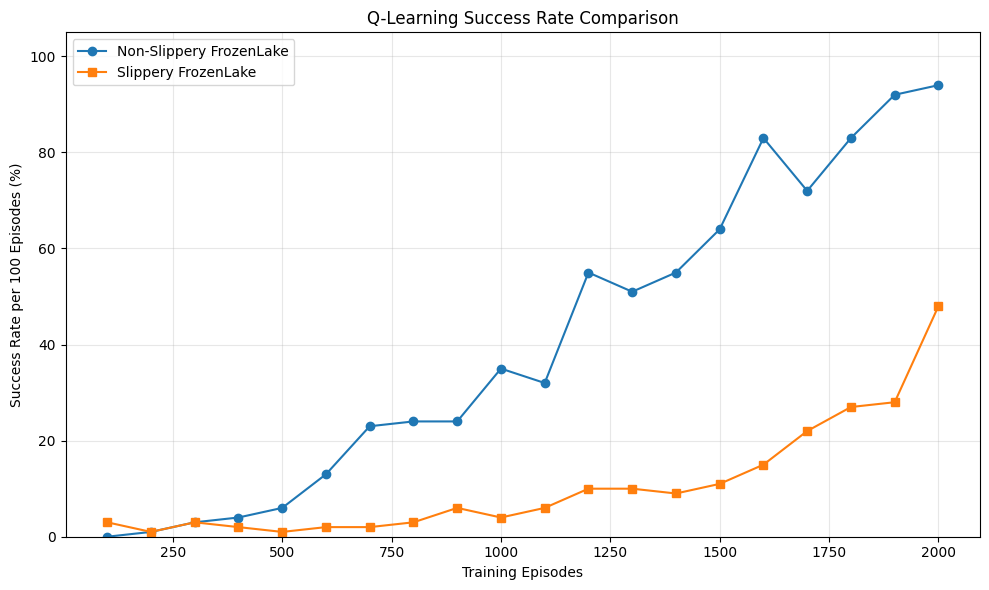

Saved: outputs/success_rate.png

FINAL 100-EPISODE SUCCESS RATES
Non-slippery: 94.00%
Slippery: 48.00%


In [21]:

# Task 7(d): Compare FrozenLake learning curves

# Episodes at which we recorded success rates
episode_points = np.arange(100, episodes + 1, 100)

# Create the comparison graph
plt.figure(figsize=(10, 6))

plt.plot(
    episode_points,
    np.array(success_rates) * 100,
    marker="o",
    label="Non-Slippery FrozenLake"
)

plt.plot(
    episode_points,
    np.array(slippery_success_rates) * 100,
    marker="s",
    label="Slippery FrozenLake"
)

# Add chart title and labels
plt.title("Q-Learning Success Rate Comparison")
plt.xlabel("Training Episodes")
plt.ylabel("Success Rate per 100 Episodes (%)")

plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)

# Save the required graph
plt.tight_layout()
plt.savefig("outputs/success_rate.png", dpi=150)

# Display the graph
plt.show()

print("Saved: outputs/success_rate.png")

print("\nFINAL 100-EPISODE SUCCESS RATES")
print(f"Non-slippery: {success_rates[-1]:.2%}")
print(f"Slippery: {slippery_success_rates[-1]:.2%}")


In [22]:

# Task 7(d): Display the slippery FrozenLake policy

# FrozenLake actions: Left, Down, Right, Up
arrows = ["←", "↓", "→", "↑"]

# Create an environment to read the lake layout
policy_env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

lake = policy_env.unwrapped.desc

print("LEARNED POLICY: SLIPPERY FROZENLAKE")

for row in range(4):
    policy_row = []

    for col in range(4):
        state = row * 4 + col
        symbol = lake[row, col].decode("utf-8")

        if symbol in ["H", "G"]:
            policy_row.append(symbol)
        else:
            action = int(np.argmax(Q_slippery[state]))
            policy_row.append(arrows[action])

    print("  ".join(policy_row))

policy_env.close()

print("\nPolicy displayed successfully!")


LEARNED POLICY: SLIPPERY FROZENLAKE
←  ↑  ←  ↑
←  H  ←  H
↑  ↓  ←  H
H  →  ↓  G

Policy displayed successfully!



### Task 7(d): Exam Skill — Manual Q-Learning Update

During non-slippery FrozenLake training, I recorded the following update:

State = 14

Action = 2 (Right)

Q-value before update = 0.0

Reward = 1.0

Best next Q-value = 0.0

Learning rate (alpha) = 0.1

Discount factor (gamma) = 0.99

**Q-Learning Formula**

Q_new = Q_old + alpha × (reward + gamma × best_next_Q - Q_old)

**Substituting the values**

Q_new = 0.0 + 0.1 × (1.0 + 0.99 × 0.0 - 0.0)

Q_new = 0.0 + 0.1 × 1.0

**Q_new = 0.1**

This matches the Q-value calculated by Python.

Alpha controls how quickly the agent updates its knowledge. Gamma controls the importance of future rewards. Epsilon determines how often the agent explores rather than selecting its currently preferred action.


## Part a) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# a1. <what this cell does>


## Part b) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# b1. <what this cell does>


## Part c) <title of the part, copied from the practical>

Write a python code to:
1. <step 1>
2. <step 2>

In [ ]:
# c1. <what this cell does>


## Written answer


## Task 7: Written Answer — Unsupervised and Reinforcement Learning

### Part A: Clustering

I used K-Means clustering on 5,000 loan records using five standardised numerical features.

The best number of clusters was k = 2, with a silhouette score of 0.2416. This suggests the groups have some overlap.

**Cluster 0: Smaller Loans and Lower Loan-to-Income Ratios**

This cluster contained 3,269 borrowers, with an average loan amount of 6,199.24 and an average loan-to-income ratio of 0.11. Its historical default rate was 15.30%.

**Cluster 1: Larger Loans and Higher Loan-to-Income Ratios**

This cluster contained 1,731 borrowers, with an average loan amount of 16,057.24 and an average loan-to-income ratio of 0.27. Its historical default rate was 33.62%.

PCA reduced the five features to two principal components, explaining 62.16% of the total variation in the data.

DBSCAN used eps = 1.0 and min_samples = 5. It identified one main cluster containing 4,888 borrowers and 112 noise points.

The noise group had a historical default rate of 42.86%, compared with 21.15% for the main DBSCAN cluster.

DBSCAN is useful for detecting unusual applicants because it can identify isolated records as noise rather than forcing every record into a cluster. A noise label does not automatically mean an applicant will default.

### Part B: Q-Learning

I implemented Q-learning using FrozenLake-v1 with a Q-table containing 16 states and 4 actions.

I trained the agent for 2,000 episodes using a learning rate (alpha) of 0.1, a discount factor (gamma) of 0.99 and a decaying epsilon-greedy exploration policy.

Alpha controls how quickly Q-values are updated, while gamma determines how much the agent values future rewards. Epsilon controls how often the agent explores instead of choosing its currently preferred action.

In the non-slippery environment, the agent achieved a success rate of 94% in the final 100 training episodes.

When I repeated the experiment with is_slippery=True, the final 100-episode success rate was 48%.

The slippery lake is harder because the agent's chosen action does not always produce the intended movement, increasing the risk of falling into holes.

This experiment demonstrates that uncertainty makes reinforcement learning more challenging and that a policy learned in a predictable environment may not perform equally well in an uncertain environment.


## Reviews

### Review by <Name>
A check, an improvement or a question.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [23]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 7
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
